# 02 · The evidence behind each `BUB1B` allele

**Place in the argument.** Track 1, curation. The ranking proposes a gene; this notebook checks,
allele by allele, what evidence supports each one and what prevents the pair from being closed.

**Main output.** QC of the two calls, ACMG-style curation, and the geometry of nonsense-mediated
decay (NMD) and phase. It does not turn a VUS into a pathogenic variant, or an unknown phase into
*trans*.

> **Sanitised output.** No positions, no amino-acid identities, no coordinates. The alleles are
> named by their role (`truncating`, `missense`), which is what curation needs.
>
> **This is research curation, not a clinical report.** The project delivers a falsifiable
> hypothesis, never a recommendation.

## The biological question

**What supports each allele on its own, and what would it take for the pair to be causal?**

## Hypothesis and preregistration

`docs/DECISIONS.md`. The `PP3` thresholds were sealed **before** REVEL was looked at, precisely
so that an uninformative predictor could not be added when convenient.

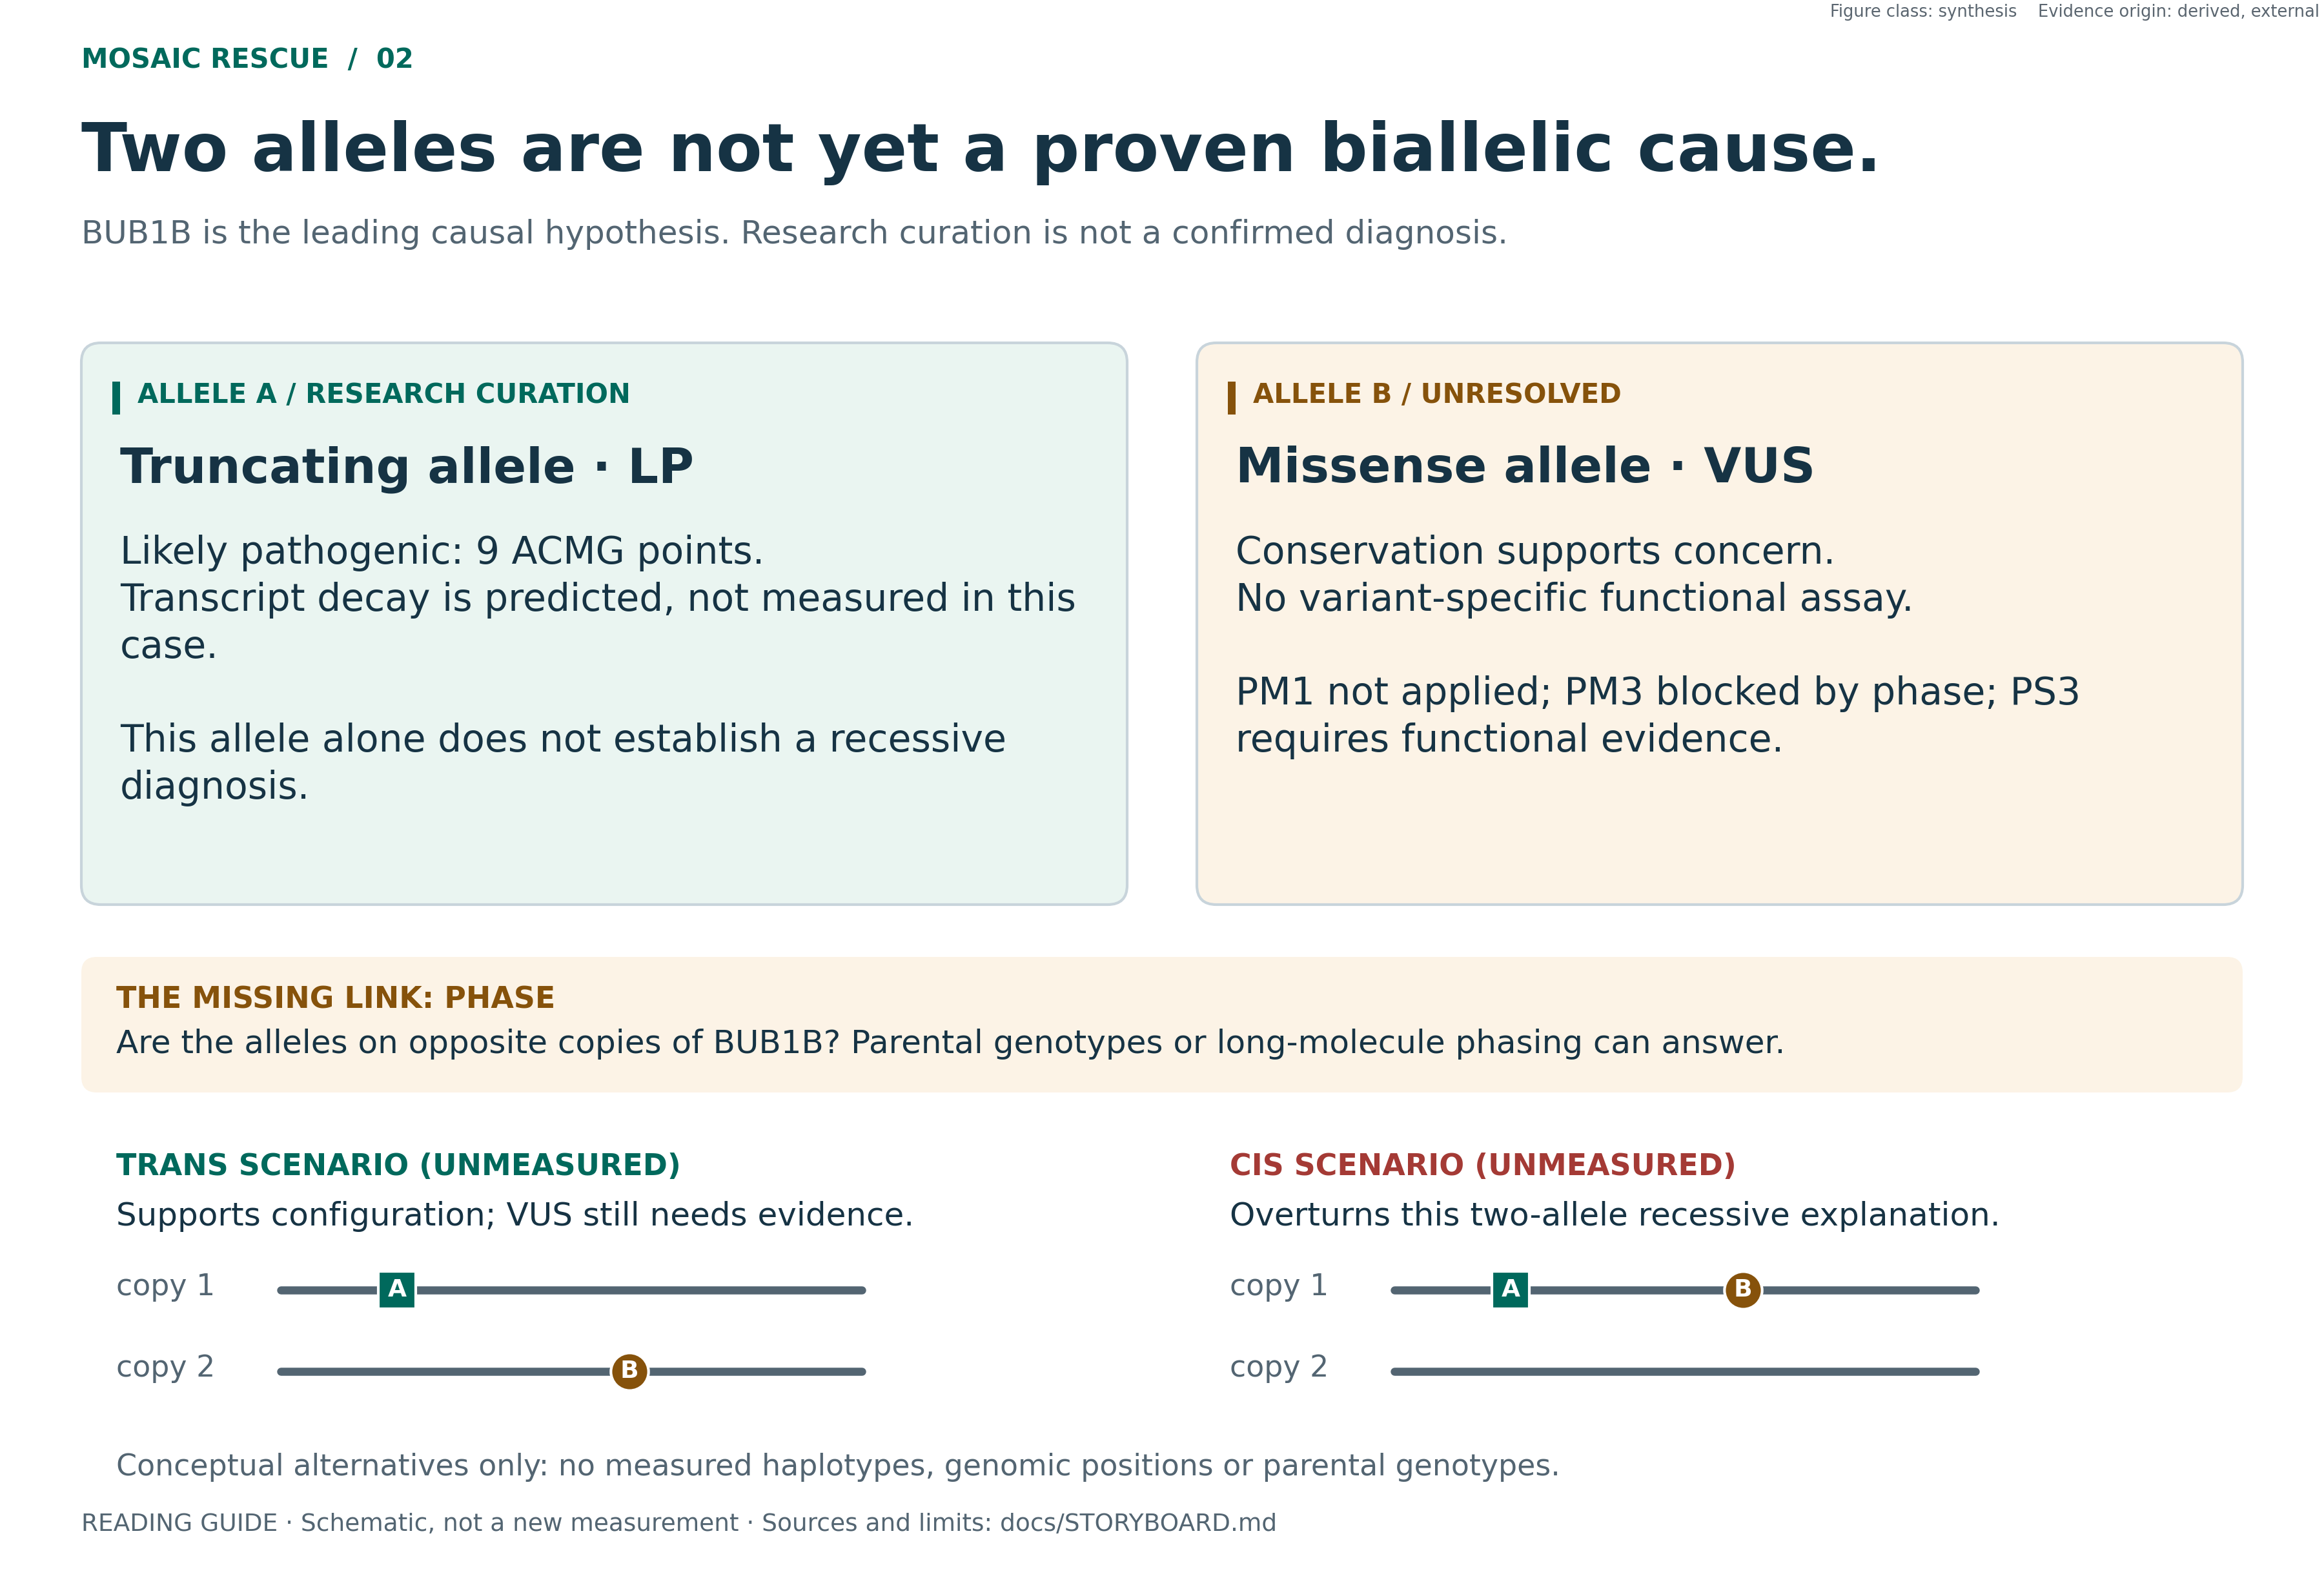

**`SYNTHESIS` · DERIVED / EXTERNAL.** Two prioritised alleles; phase unresolved. Cis and trans are conceptual scenarios, not measured haplotypes. Reviewed figure, embedded without re-running the original analysis · [sources and limits](../docs/STORYBOARD.md) · [figure QA](../PUBLICATION_FIGURE_QA.md)

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # the pipeline uses paths relative to the repo root
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # inline figures + provenance captions
print("environment ready · figures in this notebook render inline, each with a provenance caption")

environment ready · figures in this notebook render inline, each with a provenance caption


In [2]:
fl.labels("Interpretation", "Limit of the evidence")

## Inputs · QC of the two calls

Before curating anything: are the calls good? Curation on a bad call is noise formatted as
ACMG. Each allele is placed against the same metric for every heterozygous HIGH/MODERATE call in
this genome, which is the reference a single number needs.

In [3]:
from src.paths import patient_vcf
from src.prioritization.genome_wide import load

rows = load("work/gw/highmod_ann.tsv", patient_vcf())
seen, alleles = set(), []
for v in rows:
    if v.gene != "BUB1B" or v.impact not in ("HIGH", "MODERATE"):
        continue
    k = (v.loc, v.allele)
    if k in seen:
        continue
    seen.add(k); alleles.append(v)

ROLE = {"HIGH": "allele A · truncating", "MODERATE": "allele B · missense"}
# The raw GT field is NOT printed: it is the patient's genotype in exactly the format the hard
# rule forbids versioning. Zygosity is stated in words, because that is already the project's
# canonical claim. The rest are call-quality metrics, which is what this QC evaluates.
ZYG = {"0/1": "heterozygous", "1|0": "heterozygous", "0|1": "heterozygous",
       "1/1": "homozygous alternate"}
for v in alleles:
    ab = v.allele_balance
    print(f"  {ROLE.get(v.impact, v.impact):<24} {ZYG.get(v.gt, 'zygosity unresolved'):<14}"
          f"DP={v.dp}  GQ={v.gq}  AB={ab:.2f}  FILTER={v.filt}  MAX_AF="
          f"{('%.2e' % v.max_af) if v.max_af is not None else 'ABSENT'}")

# Background: every heterozygous HIGH/MODERATE call in the genome, one entry per allele
bg, seen_bg = [], set()
for v in rows:
    if v.impact in ("HIGH", "MODERATE") and v.gt in ("0/1", "0|1", "1|0") \
            and (v.loc, v.allele) not in seen_bg and v.allele_balance is not None:
        seen_bg.add((v.loc, v.allele)); bg.append(v)
print(f"\n  background: {len(bg):,} heterozygous HIGH/MODERATE calls")

  allele A · truncating    heterozygous  DP=46  GQ=99  AB=0.54  FILTER=PASS  MAX_AF=9.98e-05
  allele B · missense      heterozygous  DP=28  GQ=99  AB=0.46  FILTER=PASS  MAX_AF=ABSENT

  background: 8,587 heterozygous HIGH/MODERATE calls


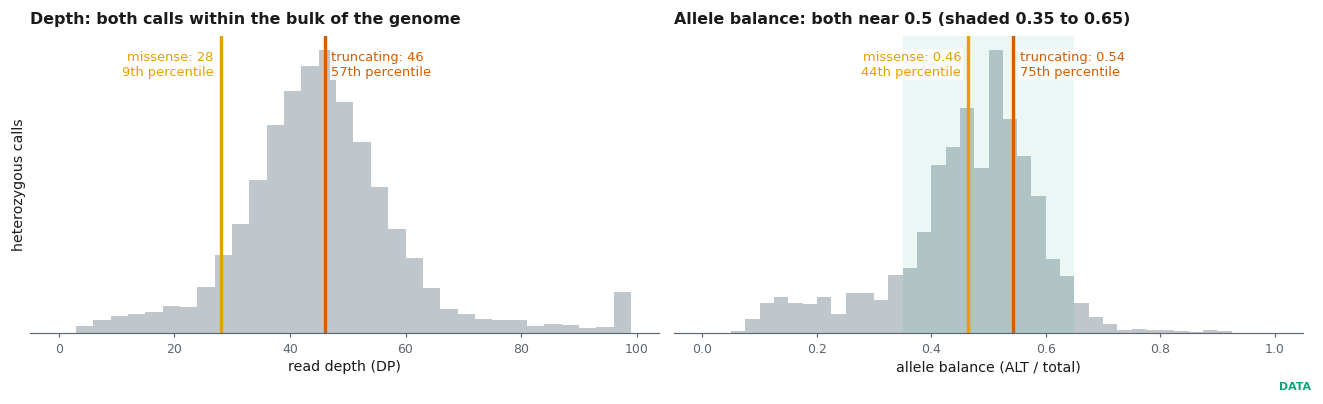

> **QC figure · the two calls against every heterozygous call in the genome**  
> `EXP-007` · figure class `DATA`, scientific figure · evidence origin `MEASURED`  
> *Interpretation.* both alleles are ordinary, well-supported heterozygous calls: depth is within the bulk of the genome's heterozygous HIGH/MODERATE calls, allele balance is near 0.5, and both have the maximum genotype quality (GQ 99). Nothing about the calls argues for an artefact.  
> **Limit of the evidence.** causality: good calls are a precondition, not evidence. Allele balance serves QC and mosaicism screening; it does NOT establish that the alleles sit on opposite copies of the gene.  
> provenance: `patient VCF, joined by allele identity`

In [4]:
# Genotype quality is not drawn: both calls sit at the caller's GQ ceiling of 99, as do most
# heterozygous calls, so a histogram would carry no information.
fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.3))
MET = [("DP", "read depth (DP)", [v.dp for v in bg], lambda v: v.dp, np.arange(0, 101, 3)),
       ("AB", "allele balance (ALT / total)", [v.allele_balance for v in bg],
        lambda v: v.allele_balance, np.linspace(0, 1, 41))]
COL = {"HIGH": fl.DEAD, "MODERATE": fl.OPEN}
for ax, (key, xlabel, vals, get, bins) in zip(axes, MET):
    vals = np.clip(np.asarray(vals, float), bins[0], bins[-1])
    ax.hist(vals, bins=bins, color=fl.FLOW, alpha=0.55, lw=0)
    for v in alleles:
        x = get(v)
        pct = 100 * np.mean(np.asarray([get(b) for b in bg], float) <= x)
        ax.axvline(x, color=COL[v.impact], lw=2)
        right = v.impact == "HIGH"
        ax.text(x + (0.012 if right else -0.012) * (bins[-1] - bins[0]), ax.get_ylim()[1] * 0.95,
                f"{ROLE[v.impact].split('·')[1].strip()}: {x:.2f}".replace(".00", "") + f"\n{pct:.0f}th percentile",
                color=COL[v.impact], fontsize=7.8, va="top", ha="left" if right else "right",
                bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.2))
    if key == "AB":
        ax.axvspan(0.35, 0.65, color=fl.ALIVE, alpha=0.08, lw=0)
    ax.set_xlabel(xlabel); ax.grid(axis="y"); ax.set_yticks([])
    ax.spines["left"].set_visible(False)
axes[0].set_ylabel("heterozygous calls")
fl.title(axes[0], "Depth: both calls within the bulk of the genome")
fl.title(axes[1], "Allele balance: both near 0.5 (shaded 0.35 to 0.65)")

fl.done(fig, "QC figure · the two calls against every heterozygous call in the genome",
        "EXP-007", "MEASURED", "DATA",
        "both alleles are ordinary, well-supported heterozygous calls: depth is within the bulk "
        "of the genome's heterozygous HIGH/MODERATE calls, allele balance is near 0.5, and both "
        "have the maximum genotype quality (GQ 99). Nothing about the calls argues for an artefact.",
        "causality: good calls are a precondition, not evidence. Allele balance serves QC and "
        "mosaicism screening; it does NOT establish that the alleles sit on opposite copies of the gene.",
        prov="patient VCF, joined by allele identity")

## Primary result 1 · the anatomy of the gene, with all of ClinVar on top

Curation needs to know **where** each allele falls in the gene. The transcript model and domains
come from **Ensembl REST**, and the variant landscape is the **1 497 ClinVar missense records**
for this gene, one by one.

> The Ensembl request carries only the symbol `BUB1B`. **No patient data leaves the machine.**
> The case positions enter only as marks on the axis, without numbers.

In [5]:
from src.structure.transcript_model import fetch
T = fetch()                                   # cached in work/struct/transcript.json
L = T["translation"]["length"]
DOM = [d for d in T["domains"] if d["type"] in ("Pfam", "Gene3D")]
EX  = [e for e in T["exons"] if e.get("aa")]

print(f"  Ensembl release {T['release']} · {T['transcript']} [{T['transcript_pick']}]")
print(f"  {T['n_exons']} exons · protein {L} aa · CDS {T['translation']['cds_len']:,} nt")
for d in DOM:
    print(f"    {d['type']:<8}{d['start']:>5}-{d['end']:<5} {d['desc'][:52]}")

cv = json.load(io.open("work/clinvar/landscape_missense.json", encoding="utf-8"))
tot = cv["totals"]
per = collections.defaultdict(collections.Counter)
for v in cv["variants"]:
    per[v["pos"]][v["cls"]] += 1
print()
print(f"  ClinVar missense records in the gene: {len(cv['variants']):,} "
      f"over {len(per):,} distinct residues")
for k, v in tot.items():
    k = {"CONFLICTIVA": "conflicting", "otra": "other"}.get(k, k)   # keys as stored in the snapshot
    print(f"    {k:<12}{v:>6}  ({100*v/sum(tot.values()):.1f} %)")

  Ensembl release 116 · ENST00000287598 [canonical]
  23 exons · protein 1050 aa · CDS 3,153 nt
    Gene3D     46-203   
    Pfam       57-179   Mad3/Bub1 homology region 1
    Gene3D    782-1042  Transferase(Phosphotransferase) domain 1

  ClinVar missense records in the gene: 1,497 over 835 distinct residues
    VUS           1426  (95.3 %)
    B/LB            35  (2.3 %)
    other            7  (0.5 %)
    conflicting     28  (1.9 %)
    P/LP             1  (0.1 %)


### Main figure 1 · gene browser: exons, domains and ClinVar

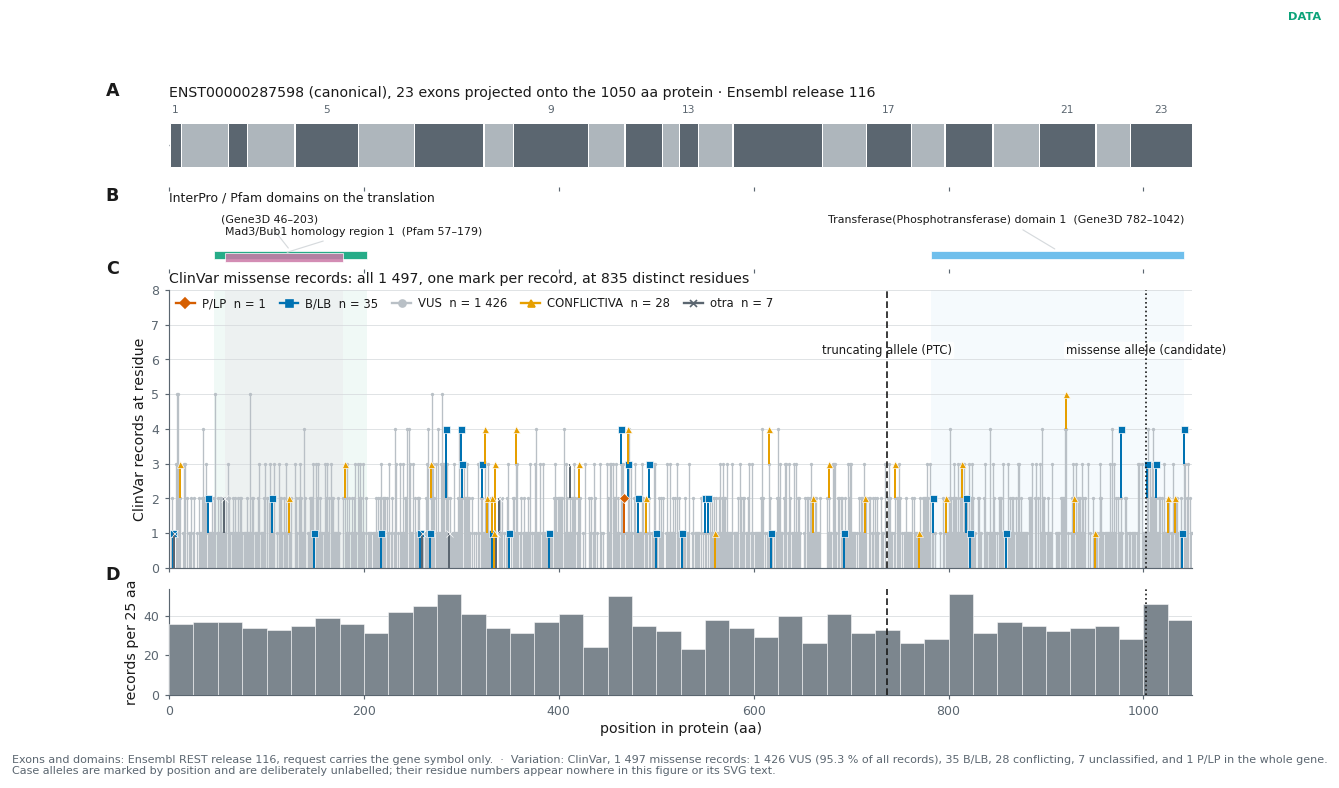

> **Main figure 1 · gene browser: exons, domains and ClinVar**  
> `EXP-007` · figure class `DATA`, scientific figure · evidence origin `EXTERNAL`  
> *Interpretation.* the real anatomy of the canonical transcript (23 exons, 1050 aa), the domains Ensembl annotates on the translation, and the 1,497 missense records ClinVar holds for the gene, one mark per record. 95.3 % are VUS, 28 have conflicting interpretations, and there is a SINGLE P/LP in the whole gene: there is no demonstrable hotspot anywhere, which is why PM1 does not apply here or anywhere else. Panel D turns the records into a readable distribution; the two vertical guides place the case alleles in that anatomy.  
> **Limit of the evidence.** that falling inside a domain means pathogenicity. ClinVar density mostly reflects how much the gene has been sequenced and reported, not where the mutations that matter lie; and the absence of a hotspot is NOT evidence against the candidate.  
> data: `Ensembl REST release 116 + work/clinvar/landscape_missense.json (1 497 records)` · library: `dna_features_viewer + matplotlib` · provenance: `figures/pub/fig02_gene_browser.svg + .png 300 dpi`

In [6]:
from src.figures import fig02_browser as FB

g = json.load(io.open("work/struct/fig3_exons.json", encoding="utf-8"))
fig = FB.build(T, cv, {"ptc_aa": g["ptc_cds"] // 3 + 1, "mis_aa": g["mis_cds"] // 3 + 1})
fl.pub(fig, "Main figure 1 · gene browser: exons, domains and ClinVar",
       "EXP-007", "EXTERNAL", "DATA",
       f"the real anatomy of the canonical transcript ({T['n_exons']} exons, {L} aa), the "
       f"domains Ensembl annotates on the translation, and the {len(cv['variants']):,} missense "
       f"records ClinVar holds for the gene, one mark per record. "
       f"{100*tot['VUS']/sum(tot.values()):.1f} % are VUS, {tot.get('CONFLICTIVA', 0)} have "
       f"conflicting interpretations, and there is a SINGLE P/LP in the whole gene: there is no "
       f"demonstrable hotspot anywhere, which is why PM1 does not apply here or anywhere else. "
       f"Panel D turns the records into a readable distribution; the two vertical guides place "
       f"the case alleles in that anatomy.",
       "that falling inside a domain means pathogenicity. ClinVar density mostly reflects how "
       "much the gene has been sequenced and reported, not where the mutations that matter lie; "
       "and the absence of a hotspot is NOT evidence against the candidate.",
       source="Ensembl REST release " + str(T["release"]) +
              " + work/clinvar/landscape_missense.json (1 497 records)",
       lib="dna_features_viewer + matplotlib", slug="fig02_gene_browser")

## Primary result 2 · the missense landscape in ClinVar

`PM1`, `PS1` and `PM5` are assessed on the comparable class. The error this corrected: counting
"0 P/LP against 35 B/LB" mixed every consequence type; **31 of those 35 were synonymous**.

In [7]:
d = json.load(io.open("work/clinvar/landscape_missense.json", encoding="utf-8"))
tot = d["totals"]
LBL = {"CONFLICTIVA": "conflicting", "otra": "other"}
rows_md = ["| ClinVar class (missense only, whole gene) | records | share |", "|---|---:|---:|"]
for k, v in tot.items():
    rows_md.append(f"| {LBL.get(k, k)} | {v:,} | {100*v/sum(tot.values()):.1f} % |")
from IPython.display import Markdown, display
display(Markdown("\n".join(rows_md) + "\n\nNo residue of the gene has a demonstrable hotspot, "
                 "so PM1 does not apply **anywhere**."))

| ClinVar class (missense only, whole gene) | records | share |
|---|---:|---:|
| VUS | 1,426 | 95.3 % |
| B/LB | 35 | 2.3 % |
| other | 7 | 0.5 % |
| conflicting | 28 | 1.9 % |
| P/LP | 1 | 0.1 % |

No residue of the gene has a demonstrable hotspot, so PM1 does not apply **anywhere**.

## Primary result 3 · the geometry of NMD and of phase

Two geometric measurements decide two different things: whether the truncating allele triggers
NMD, and whether the two alleles can be connected with short reads.

In [8]:
import re
g = json.load(io.open("work/struct/fig3_exons.json", encoding="utf-8"))
EXN, ptc, mis, last = g["exons"], g["ptc_cds"], g["mis_cds"], g["last_junction"]
margin = last - ptc
# Genomic distances between the two alleles and the single informative heterozygote between
# them, measured from the VCF when figures/fig3 was built. Only DIFFERENCES are used here; no
# absolute coordinate is printed or drawn.
_src = io.open("src/make_fig3.py", encoding="utf-8").read()
GA, GH, GB = map(int, re.search(r"GA, GH, GB = (\d+), (\d+), (\d+)", _src).groups())
d_ah, d_hb, d_ab = GH - GA, GB - GH, GB - GA
FRAG = 300
print(f"  PTC to the last exon-exon junction : {margin:,} nt  (rule: 50-55 nt) -> ~{margin/52:.0f}x the threshold")
print(f"  distance between the two alleles   : {d_ab:,} bp")
print(f"  informative heterozygotes between  : 1  ({d_ah:,} bp and {d_hb:,} bp from each allele)")
print(f"  shortest gap / library fragment    : {d_hb:,} / ~{FRAG} bp = {d_hb/FRAG:.1f}x")

  PTC to the last exon-exon junction : 748 nt  (rule: 50-55 nt) -> ~14x the threshold
  distance between the two alleles   : 10,911 bp
  informative heterozygotes between  : 1  (6,769 bp and 4,142 bp from each allele)
  shortest gap / library fragment    : 4,142 / ~300 bp = 13.8x


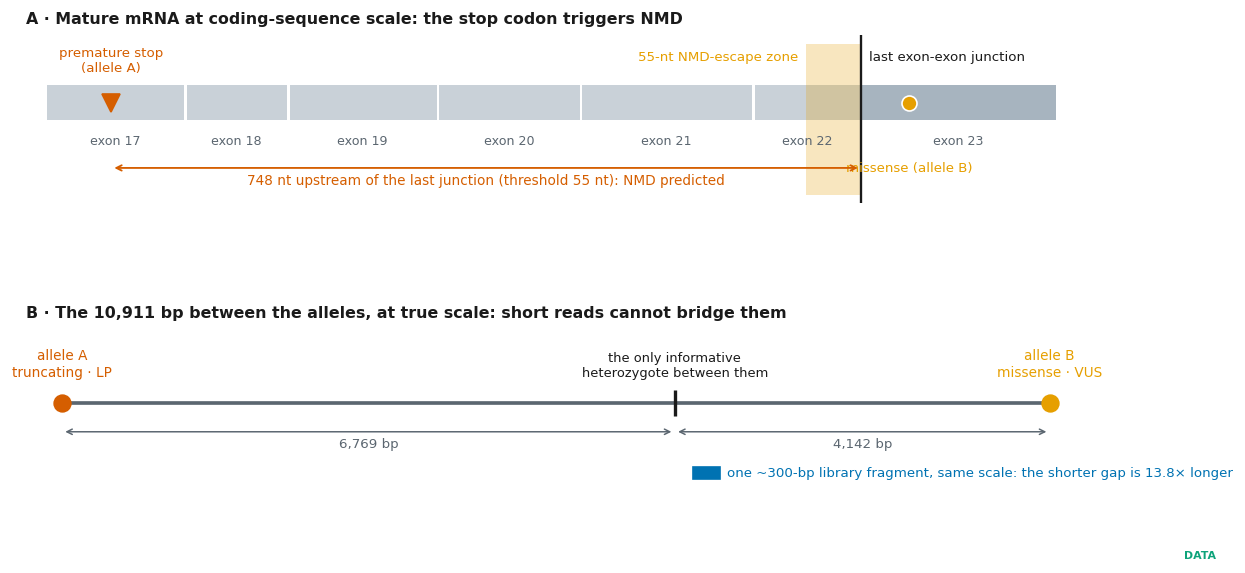

> **Main figure 3 · the geometry of NMD and of phase**  
> `EXP-007 · EXP-013` · figure class `DATA`, scientific figure · evidence origin `MEASURED+DERIVED`  
> *Interpretation.* the premature stop lies 748 nt upstream of the last exon-exon junction, far beyond the 50-55 nt rule: NMD is predicted with a wide margin. Below, why phase cannot be resolved: 10,911 bp separate the two alleles, with a single informative heterozygote between them, against library fragments of ~300 bp.  
> **Limit of the evidence.** that the alleles sit on opposite copies of the gene. `unphased` is not `trans`: the longest phase block in the whole genome is 288 bp. Unresolved phase STAYS unresolved; only parental genotypes or long-molecule phasing can settle it.  
> provenance: `work/struct/fig3_exons.json (exon limits probed at 2 bp) + VCF distances in src/make_fig3.py`

In [9]:
fig = plt.figure(figsize=(11.4, 5.0))
gs = fig.add_gridspec(2, 1, height_ratios=[1.0, 1.0], hspace=0.75)
axA, axB = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

# A · the mature mRNA, CDS scale, last seven exons
c0 = EXN[0]["c0"]
for e in EXN:
    last_ex = e is EXN[-1]
    axA.add_patch(plt.Rectangle((e["c0"] - c0, 0), e["c1"] - e["c0"] + 1, 1,
                                fc="#C9D1D8" if not last_ex else "#A7B4BF", ec="white", lw=1.2))
    axA.text((e["c0"] + e["c1"]) / 2 - c0, -0.35, f"exon {e['n']}", ha="center", va="top",
             fontsize=7.6, color=fl.SOFT)
axA.axvspan(last - 55 - c0, last - c0, ymin=0.05, ymax=0.95, color=fl.OPEN, alpha=0.25, lw=0)
axA.axvline(last - c0, color=fl.INK, lw=1.4)
axA.text(last - c0 + 8, 1.55, "last exon-exon junction", fontsize=8, va="bottom")
axA.text(last - 55 - c0 - 8, 1.55, "55-nt NMD-escape zone", fontsize=8, color=fl.OPEN,
         ha="right", va="bottom")
axA.plot([ptc - c0], [0.5], marker="v", ms=11, color=fl.DEAD, zorder=4)
axA.text(ptc - c0, 1.25, "premature stop\n(allele A)", ha="center", va="bottom", fontsize=8,
         color=fl.DEAD)
axA.plot([mis - c0], [0.5], marker="o", ms=9, color=fl.OPEN, mec="white", zorder=4)
axA.text(mis - c0, -1.25, "missense (allele B)", ha="center", va="center", fontsize=8, color=fl.OPEN)
axA.annotate("", xy=(last - c0, -1.25), xytext=(ptc - c0, -1.25),
             arrowprops=dict(arrowstyle="<->", color=fl.DEAD, lw=1.1))
axA.text((ptc + last) / 2 - c0, -1.4, f"{margin:,} nt upstream of the last junction "
         f"(threshold 55 nt): NMD predicted", ha="center", va="top", fontsize=8.2, color=fl.DEAD)
axA.set_xlim(-20, EXN[-1]["c1"] - c0 + 30); axA.set_ylim(-2.2, 2.3)
axA.axis("off")
fl.title(axA, "A · Mature mRNA at coding-sequence scale: the stop codon triggers NMD")

# B · the genomic interval, at true scale, with a library fragment drawn to the same scale
axB.plot([0, d_ab], [0, 0], color=fl.SOFT, lw=2.2, solid_capstyle="butt")
for x, lab, c in ((0, "allele A\ntruncating · LP", fl.DEAD), (d_ab, "allele B\nmissense · VUS", fl.OPEN)):
    axB.plot([x], [0], marker="o", ms=10, color=c, zorder=3)
    axB.text(x, 0.45, lab, ha="center", va="bottom", fontsize=8.2, color=c)
axB.plot([d_ah], [0], marker="|", ms=16, mew=2, color=fl.INK)
axB.text(d_ah, 0.45, "the only informative\nheterozygote between them", ha="center", va="bottom",
         fontsize=7.8, color=fl.INK)
for a, b, y in ((0, d_ah, -0.55), (d_ah, d_ab, -0.55)):
    axB.annotate("", xy=(b, y), xytext=(a, y), arrowprops=dict(arrowstyle="<->", color=fl.SOFT, lw=0.9))
    axB.text((a + b) / 2, y - 0.12, f"{b - a:,} bp", ha="center", va="top", fontsize=8, color=fl.SOFT)
axB.add_patch(plt.Rectangle((d_ah + 200, -1.45), FRAG, 0.22, color=fl.BLUE))
axB.text(d_ah + 200 + FRAG + 80, -1.34, f"one ~{FRAG}-bp library fragment, same scale: "
         f"the shorter gap is {d_hb/FRAG:.1f}× longer", va="center", fontsize=8, color=fl.BLUE)
axB.set_xlim(-400, d_ab + 400); axB.set_ylim(-1.8, 1.4); axB.axis("off")
fl.title(axB, f"B · The {d_ab:,} bp between the alleles, at true scale: short reads cannot bridge them")

fl.done(fig, "Main figure 3 · the geometry of NMD and of phase", "EXP-007 · EXP-013",
        "MEASURED+DERIVED", "DATA",
        f"the premature stop lies {margin:,} nt upstream of the last exon-exon junction, far "
        "beyond the 50-55 nt rule: NMD is predicted with a wide margin. Below, why phase cannot "
        f"be resolved: {d_ab:,} bp separate the two alleles, with a single informative "
        f"heterozygote between them, against library fragments of ~{FRAG} bp.",
        "that the alleles sit on opposite copies of the gene. `unphased` is not `trans`: the longest phase block in the "
        "whole genome is 288 bp. Unresolved phase STAYS unresolved; only parental genotypes or "
        "long-molecule phasing can settle it.",
        prov="work/struct/fig3_exons.json (exon limits probed at 2 bp) + VCF distances in src/make_fig3.py")

## Robustness · the ceiling of each allele, and what would move it

Curation does not end at a label: it ends knowing **how much evidence is missing, and of what
kind**. The scale is ClinGen's Bayesian points framework (VUS 0–5, likely pathogenic 6–9,
pathogenic ≥ 10).

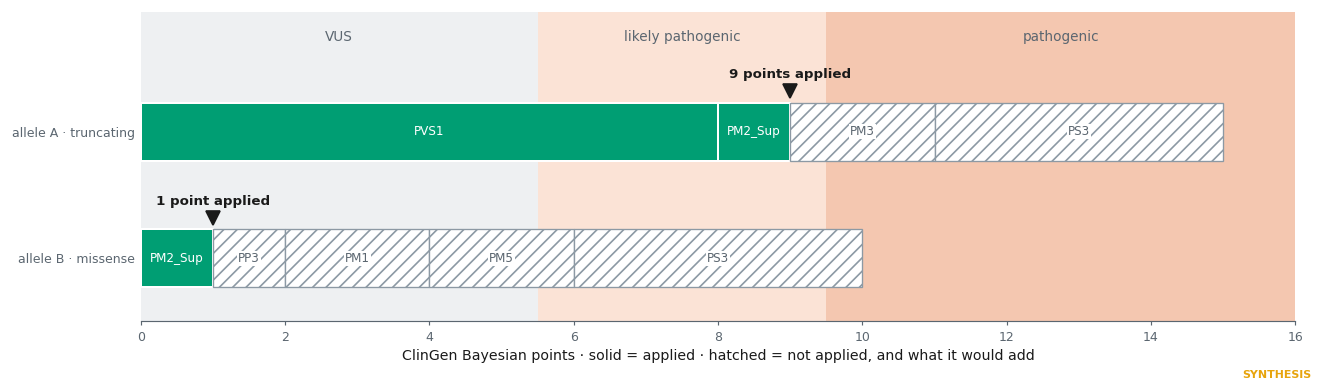

> **Robustness figure · ACMG points applied, and those still missing**  
> `EXP-007` · figure class `SYNTHESIS`, not data: synthesis · evidence origin `DERIVED`  
> *Interpretation.* the truncating allele reaches 9 points (PVS1 + PM2_Supporting): likely pathogenic. The missense has 1: it stays a VUS, and would stay a VUS even with PP3, because PM1 and PM5 cannot apply in a gene without a hotspot or a prior pathogenic change at the residue. Only functional evidence (PS3) can move it.  
> **Limit of the evidence.** that criteria not applied are evidence against. PM3 is blocked BY DECISION, more conservative than ClinGen, because phase is unresolved; PP3 does not apply because REVEL gave 0.472, below the threshold sealed BEFORE it was looked at.  
> provenance: `docs/ACMG_CURATION.md · thresholds preregistered in DECISIONS.md`

In [10]:
# ClinGen Bayesian points framework, as applied
EVID = {
 "allele A · truncating": [("PVS1", 8, True), ("PM2_Supporting", 1, True),
                            ("PM3", 2, False), ("PS3", 4, False)],
 "allele B · missense":   [("PM2_Supporting", 1, True), ("PP3", 1, False), ("PM1", 2, False),
                            ("PM5", 2, False), ("PS3", 4, False)],
}
BANDS = [(0, 5.5, "VUS", "#EEF0F2"), (5.5, 9.5, "likely pathogenic", "#FBE3D6"),
         (9.5, 16, "pathogenic", "#F4C7B0")]
fig, ax = plt.subplots(figsize=(11.0, 3.2))
for x0, x1, lab, c in BANDS:
    ax.axvspan(x0, x1, color=c, lw=0, zorder=0)
    ax.text((x0 + x1) / 2, 1.72, lab, ha="center", fontsize=8.2, color=fl.SOFT)
for yi, (name, items) in enumerate(EVID.items()):
    y = 1 - yi
    x = 0
    for code, p, ok in items:
        if ok:
            ax.barh(y, p, left=x, height=0.46, color=fl.ALIVE, ec="white", lw=1.2, zorder=2)
        else:
            ax.barh(y, p, left=x, height=0.46, fc="white", ec=fl.FLOW, hatch="///", lw=0.8, zorder=2)
        ax.text(x + p / 2, y, code.replace("_Supporting", "_Sup"), ha="center", va="center",
                fontsize=7.2, color="white" if ok else fl.SOFT, zorder=3,
                bbox=None if ok else dict(fc="white", ec="none", pad=0.6))
        x += p
    applied = sum(p for _, p, ok in items if ok)
    ax.plot([applied], [y + 0.32], marker="v", ms=8, color=fl.INK, zorder=4)
    ax.text(applied, y + 0.4, f"{applied} point{'s' if applied != 1 else ''} applied", ha="center", va="bottom", fontsize=8,
            fontweight="bold")
ax.set_yticks([1, 0]); ax.set_yticklabels(list(EVID)); ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 16); ax.set_ylim(-0.5, 1.95); ax.grid(False)
ax.spines["left"].set_visible(False)
ax.set_xlabel("ClinGen Bayesian points · solid = applied · hatched = not applied, and what it would add")

fl.done(fig, "Robustness figure · ACMG points applied, and those still missing",
        "EXP-007", "DERIVED", "SYNTHESIS",
        "the truncating allele reaches 9 points (PVS1 + PM2_Supporting): likely pathogenic. The "
        "missense has 1: it stays a VUS, and would stay a VUS even with PP3, because PM1 and PM5 "
        "cannot apply in a gene without a hotspot or a prior pathogenic change at the residue. "
        "Only functional evidence (PS3) can move it.",
        "that criteria not applied are evidence against. PM3 is blocked BY DECISION, more "
        "conservative than ClinGen, because phase is unresolved; PP3 does not apply because "
        "REVEL gave 0.472, below the threshold sealed BEFORE it was looked at.",
        prov="docs/ACMG_CURATION.md · thresholds preregistered in DECISIONS.md")

## Contradicting evidence, declared

**SIFT `deleterious` 0.01 and PolyPhen 0.997 pointed strongly towards pathogenicity.** The
calibrated predictor says there is no assignable evidence. Adding the first two would have
produced an unjustified `PP3`: this is the size of the error the preregistration prevented.

And an error of our own: we once stated that no candidate was in dbSNP, inferring it from the
VCF's empty `ID` column. **Wrong**: that column only means the caller did not annotate it. The
truncating allele is in dbSNP, and in ClinVar as pathogenic.

## Decision

| | |
|---|---|
| **Allele A · truncating** | **Likely pathogenic** (9 points, research curation) |
| **Allele B · missense** | **VUS**, and it stays a VUS even if `PP3` were added |
| **The pair** | *one likely pathogenic truncating allele + one rare missense candidate, **phase unresolved*** |

### What it does not establish

**Compound heterozygosity is not demonstrated.** `PM3` stays blocked, phase stays unresolved, and
without that the biallelic model is a *candidate*, not established. This pair is the canonical
MVA1 configuration ([Hanks et al. 2004](https://doi.org/10.1038/ng1449)), which raises its prior
plausibility but does not replace phase or function.

### Falsifier

Parental genotypes, or targeted long-molecule phasing across the interval that separates the two
alleles. Either one turns "candidate" into resolved, **in whichever direction**.

### Next

`03_BUBR1_MECHANISM`: if the missense does not move by classification, does it move by
mechanism?